# Kiểm tra dữ liệu


## Chuẩn bị


In [1]:
"""Kiểm tra nhanh dữ liệu; chạy từ thư mục Tuan03/Lab03."""

import pandas as pd
from lab03_plots import plot_missing_values, plot_price_distribution

from notebook_loader import run_notebook_code
run_notebook_code("house_price_pipeline.ipynb", globals())




## Hàm: `main`


In [2]:
def main():
    # In kích thước, kiểu dữ liệu, giá trị thiếu và thống kê của SalePrice.
    train, test = load_competition_data("data")
    print(f"Train: {train.shape[0]} rows x {train.shape[1]} columns")
    print(f"Test:  {test.shape[0]} rows x {test.shape[1]} columns")
    print("\nTrain sample:")
    print(train.head().to_string(index=False))
    print("\nColumn data types (pandas):")
    print(train.dtypes.value_counts().to_string())
    print("\nColumn inventory: pandas dtype, missing count, example:")
    inventory = pd.DataFrame(
        {
            "dtype": train.dtypes.astype(str),
            "missing": train.isna().sum(),
            "example": [
                train[column].dropna().iloc[0] if train[column].notna().any() else "<all missing>"
                for column in train.columns
            ],
        }
    )
    # Bảng inventory giúp nhìn đồng thời kiểu dữ liệu, số ô thiếu và một ví dụ.
    print(inventory.to_string())
    print("\nMissing values in train (top 20):")
    missing = train.isna().sum().sort_values(ascending=False)
    print(missing[missing > 0].head(20).to_string())
    print("\nSalePrice summary:")
    print(train[TARGET].describe().to_string())
    print("\nTarget absent from test:", TARGET not in test.columns)
    plot_missing_values(train, "outputs/test_missing_values.png")
    plot_price_distribution(train[TARGET], "outputs/test_price_distribution.png")




## Chạy notebook


Train: 1460 rows x 81 columns
Test:  1459 rows x 80 columns

Train sample:
 Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape LandContour Utilities LotConfig LandSlope Neighborhood Condition1 Condition2 BldgType HouseStyle  OverallQual  OverallCond  YearBuilt  YearRemodAdd RoofStyle RoofMatl Exterior1st Exterior2nd MasVnrType  MasVnrArea ExterQual ExterCond Foundation BsmtQual BsmtCond BsmtExposure BsmtFinType1  BsmtFinSF1 BsmtFinType2  BsmtFinSF2  BsmtUnfSF  TotalBsmtSF Heating HeatingQC CentralAir Electrical  1stFlrSF  2ndFlrSF  LowQualFinSF  GrLivArea  BsmtFullBath  BsmtHalfBath  FullBath  HalfBath  BedroomAbvGr  KitchenAbvGr KitchenQual  TotRmsAbvGrd Functional  Fireplaces FireplaceQu GarageType  GarageYrBlt GarageFinish  GarageCars  GarageArea GarageQual GarageCond PavedDrive  WoodDeckSF  OpenPorchSF  EnclosedPorch  3SsnPorch  ScreenPorch  PoolArea PoolQC Fence MiscFeature  MiscVal  MoSold  YrSold SaleType SaleCondition  SalePrice
  1          60       RL        

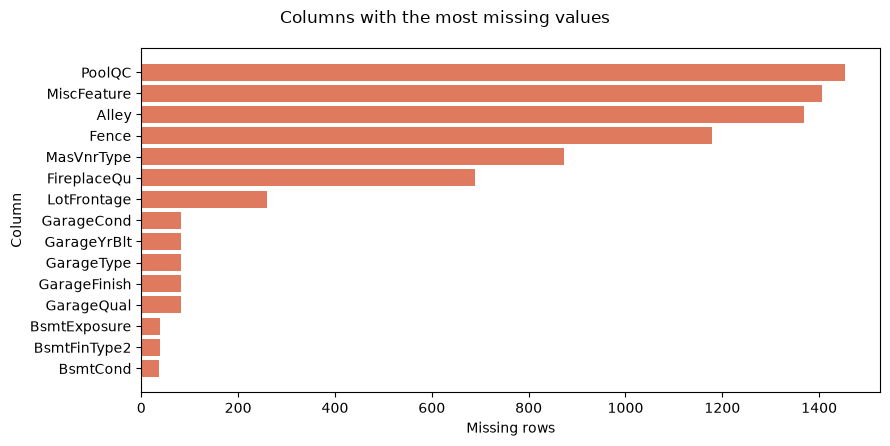

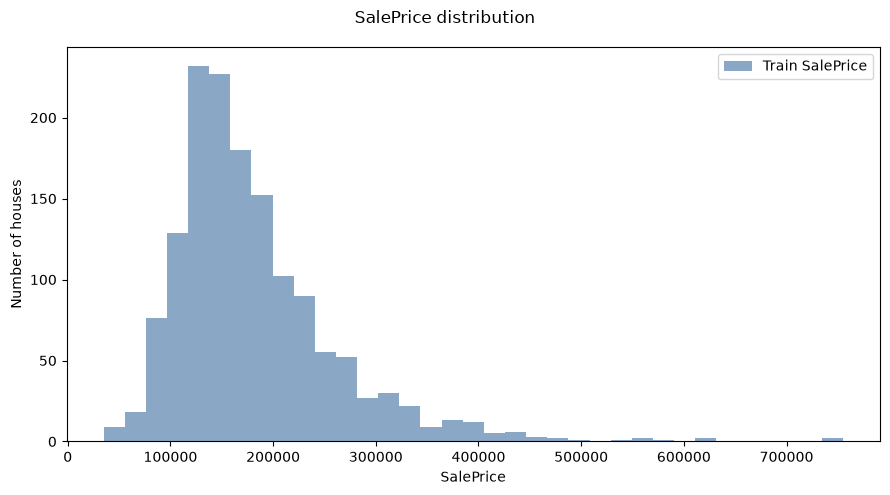

In [3]:
if __name__ == "__main__":
    main()
